In [1]:
import geopandas as gpd
from matplotlib import pyplot as plt
import pandas as pd
import networkx as nx
import h3
import numpy as np


In [3]:


# Load data
input_dir = "../data/output_files/retailcen_foursquare_mrc_2_mri_10_mrn_10_mtf_6_merge_n/"
retail_centres = gpd.read_parquet(input_dir + "3_afterfill.parquet")


def gaussian_smooth(count_dict, center_cell, sigma=1.0):
    smoothed_value = 0
    total_weight = 0
    
    # Iterate over distances (you can customize the max distance)
    for dist in range(1, 4):  # Example with distance up to 3
        neighbors = h3.grid_ring(center_cell, dist)
        for neighbor in neighbors:
            weight = np.exp(-dist**2 / (2 * sigma**2))  # Gaussian weight
            smoothed_value += count_dict.get(neighbor, 0) * weight
            total_weight += weight
    
    # Add the center cell's value
    smoothed_value += count_dict.get(center_cell, 0) * np.exp(-0 / (2 * sigma**2))  # Center cell
    total_weight += 1  # Weight of the center cell is 1
    
    return smoothed_value / total_weight if total_weight != 0 else count_dict.get(center_cell, 0)


# Apply smoothing to a DataFrame
def smooth_counts(df, sigma=1.0):
    """
    Apply Gaussian smoothing to the POI counts in the dataframe.
    
    Parameters:
    - df: The DataFrame containing H3 cells and POI counts
    - sigma: Standard deviation for the Gaussian kernel
    
    Returns:
    - df: DataFrame with a new column for smoothed counts
    """
    count_dict = dict(zip(df['h3_11'], df['foursquare_count']))  # Dictionary of H3 cells and their POI counts
    smoothed = {}

    for cell in count_dict:
        smoothed[cell] = gaussian_smooth(count_dict, cell, sigma)
    
    # Add the smoothed counts back to the DataFrame
    df['smoothed_count'] = df['h3_11'].map(smoothed)
    return df


def is_local_peak(cell, count_dict, radius=4, min_count=None, min_ratio=None):
    current = count_dict.get(cell, 0)

    if min_count is not None and current < min_count:
        return False

    neighbors = set(h3.grid_disk(cell, radius))
    neighbors.discard(cell)

    for n in neighbors:
        neighbor_val = count_dict.get(n, 0)
        if current <= neighbor_val:
            return False
        if min_ratio is not None and (current / (neighbor_val + 1e-5)) < min_ratio:
            return False

    return True



def watershed_segment(network_df):
    count_dict = dict(zip(network_df['h3_11'], network_df['smoothed_count']))  # Use smoothed counts here
    peaks = [cell for cell in count_dict if is_local_peak(cell, count_dict)]
    
    labels = {}  # h3 -> subcentre ID
    visited = set()
    frontier = []

    # Start from peaks
    for i, peak in enumerate(peaks):
        labels[peak] = i
        visited.add(peak)
        frontier.append((peak, i))

    # Flood fill from each peak
    while frontier:
        current, label = frontier.pop()
        for neighbor in h3.grid_ring(current, 1):
            if neighbor not in count_dict:
                continue  # Skip neighbors outside this network
            if neighbor in visited:
                continue
            # Only flow downhill or flat
            if count_dict[neighbor] <= count_dict[current]:
                labels[neighbor] = label
                visited.add(neighbor)
                frontier.append((neighbor, label))

    # Attach subcentre label back to DataFrame
    network_df['subcentre'] = network_df['h3_11'].map(labels).fillna(-1).astype(int)
    return network_df

def split_all_networks(df):
    return pd.concat(
        [watershed_segment(group) for _, group in df.groupby("network_number")],
        ignore_index=True
    )

# Apply smoothing to the retail centres data
retail_centres = smooth_counts(retail_centres, sigma=1)

# Now apply watershed segmentation
result_df = split_all_networks(retail_centres)

# Optionally: Save or display result_df
print(result_df.head())



             h3_11  network_number  foursquare_count  Dining and Drinking  \
0  8b09a6b6e914fff              61                 0                  NaN   
1  8b09a6b6166dfff              61                 1                  1.0   
2  8b09a6b6e934fff              61                 0                  NaN   
3  8b09a6b6e933fff              61                 0                  NaN   
4  8b09a6b6176dfff              61                 0                  NaN   

   Leisure & Travel  Community & Health  Commerce           top_category  \
0               NaN                 NaN       NaN                   None   
1               0.0                 0.0       0.0  [Dining and Drinking]   
2               NaN                 NaN       NaN                   None   
3               NaN                 NaN       NaN                   None   
4               NaN                 NaN       NaN                   None   

         dominant_type  retail_landuse  overture_count  total_overture_count  \


In [4]:

#save the result
result_df.to_parquet(input_dir + "4_subcentres_watershed.parquet")

In [5]:
def watershed_segment_steps(network_df):
    count_dict = dict(zip(network_df['h3_11'], network_df['smoothed_count']))
    peaks = [cell for cell in count_dict if is_local_peak(cell, count_dict)]

    labels = {}
    visited = set()
    frontier = []

    for i, peak in enumerate(peaks):
        labels[peak] = i
        visited.add(peak)
        frontier.append((peak, i))

    yield labels.copy()  # Yield initial state

    while frontier:
        current, label = frontier.pop()
        for neighbor in h3.grid_ring(current, 1):
            if neighbor not in count_dict or neighbor in visited:
                continue
            if count_dict[neighbor] <= count_dict[current]:
                labels[neighbor] = label
                visited.add(neighbor)
                frontier.append((neighbor, label))
        yield labels.copy()  # Yield after each expansion


In [6]:
import matplotlib.pyplot as plt

from shapely.geometry import Polygon
from IPython.display import clear_output
import time

def h3_to_geom(cell):
    return Polygon(h3.cell_to_boundary(cell))

def plot_watershed_progress(df, label_steps, delay=0.2):
    base_gdf = df.copy()
    base_gdf["geometry"] = base_gdf["h3_11"].apply(h3_to_geom)
    base_gdf = gpd.GeoDataFrame(base_gdf, geometry="geometry")

    for labels in label_steps:
        base_gdf["subcentre"] = base_gdf["h3_11"].map(labels).fillna(-1)

        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 10))
        base_gdf.plot(column="subcentre", cmap="tab20", ax=ax, edgecolor="black", linewidth=0.2)
        plt.title("Watershed Segmentation Progress")
        plt.axis("off")
        plt.show()
        time.sleep(delay)


In [7]:
def watershed_segment_steps_by_height(network_df):
    count_dict = dict(zip(network_df['h3_11'], network_df['smoothed_count']))  # POI counts
    # Sort cells by their count value in descending order (highest count first)
    sorted_cells = sorted(count_dict.keys(), key=lambda x: count_dict[x], reverse=True)

    labels = {}  # Dictionary for labels
    visited = set()  # Set of visited cells
    frontier = []  # Cells to explore

    # Function to flood from a cell
    def flood_from_cell(start_cell, label):
        visited.add(start_cell)
        frontier.append((start_cell, label))
        while frontier:
            current, label = frontier.pop()
            for neighbor in h3.grid_ring(current, 1):  # Explore neighbors
                if neighbor not in count_dict or neighbor in visited:
                    continue
                if count_dict[neighbor] <= count_dict[current]:  # Only flood downhill or flat
                    labels[neighbor] = label
                    visited.add(neighbor)
                    frontier.append((neighbor, label))

    # Step through each cell in descending order of count (start from highest)
    for peak in sorted_cells:
        if peak not in visited:  # Only start a new flood if not already visited
            label = len(labels)  # New label for a new segment
            labels[peak] = label
            flood_from_cell(peak, label)  # Flood from this peak
        yield labels.copy()  # Yield after each flood step


In [8]:
def plot_watershed_progress(df, label_steps, delay=0.2):
    base_gdf = df.copy()
    base_gdf["geometry"] = base_gdf["h3_11"].apply(h3_to_geom)
    base_gdf = gpd.GeoDataFrame(base_gdf, geometry="geometry")

    for labels in label_steps:
        base_gdf["subcentre"] = base_gdf["h3_11"].map(labels).fillna(-1)

        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 10))
        base_gdf.plot(column="subcentre", cmap="tab20", ax=ax, edgecolor="black", linewidth=0.2)
        plt.title("Watershed Segmentation Progress")
        plt.axis("off")
        plt.show()
        time.sleep(delay)

In [9]:
import numpy as np

def watershed_segment_steps_by_height_individual(network_df):
    count_dict = dict(zip(network_df['h3_11'], network_df['smoothed_count']))  # POI counts
    # Sort cells by their count value in descending order (highest count first)
    sorted_cells = sorted(count_dict.keys(), key=lambda x: count_dict[x], reverse=True)

    labels = {}  # Dictionary for labels
    visited = set()  # Set of visited cells
    frontier = []  # Cells to explore

    # Store all the steps (each individual cell flooding)
    all_steps = []  # List to store steps for visualization

    # Function to flood from a cell
    def flood_from_cell(start_cell, label):
        visited.add(start_cell)
        frontier.append((start_cell, label))
        step_labels = labels.copy()  # Copy of labels to store the state for each step
        while frontier:
            current, label = frontier.pop()
            labels[current] = label  # Assign label to current cell
            step_labels[current] = label  # Store the step for this cell flooding
            all_steps.append(step_labels.copy())  # Append the current step for visualization
            for neighbor in h3.grid_ring(current, 1):  # Explore neighbors
                if neighbor not in count_dict or neighbor in visited:
                    continue
                if count_dict[neighbor] <= count_dict[current]:  # Only flood downhill or flat
                    labels[neighbor] = label
                    visited.add(neighbor)
                    frontier.append((neighbor, label))

    # Step through each cell in descending order of count (start from highest)
    for peak in sorted_cells:
        if peak not in visited:  # Only start a new flood if not already visited
            label = len(labels)  # New label for a new segment
            labels[peak] = label
            flood_from_cell(peak, label)  # Flood from this peak
        # We yield the steps here to visualize each cell flooding
    return all_steps


In [18]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
import osmnx as ox
from IPython.display import clear_output
import time

def plot_watershed_progress_individual(df, all_steps, delay=0.2):
    base_gdf = df.copy()
    base_gdf["geometry"] = base_gdf["h3_11"].apply(h3_to_geom)
    base_gdf = gpd.GeoDataFrame(base_gdf, geometry="geometry")

    for step in all_steps:
        base_gdf["subcentre"] = base_gdf["h3_11"].map(step).fillna(-1)  # Map labels to GeoDataFrame

        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 10))
        base_gdf.plot(column="subcentre", cmap="tab20", ax=ax, edgecolor="black", linewidth=0.2)
        plt.title("Watershed Segmentation Progress (Cell-by-Cell)")
        plt.axis("off")
        plt.show()
        time.sleep(delay)  # Pause between updates




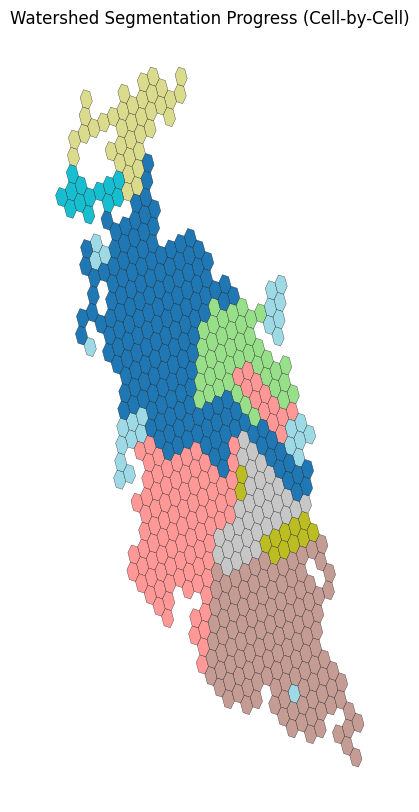

In [19]:
network_id = 43461  # <- choose your network number here
# Apply smoothing to the retail centres data
retail_centres = smooth_counts(retail_centres, sigma=1)
network_df = retail_centres[retail_centres["network_number"] == network_id]

# Get the individual flooding steps
steps = watershed_segment_steps_by_height_individual(network_df)

# Plot the flooding process
plot_watershed_progress_individual(network_df, steps, delay=0.001)



In [18]:
#load the data and make a filtered version with only the top 100 networks
retail_centres_clustered = gpd.read_parquet(input_dir + "4_subclustered_multi_resolution.parquet")

In [113]:
#rename the network_numbers by size
network_numbers = retail_centres_clustered['network_number'].value_counts().index.tolist()
network_numbers = {k: i for i, k in enumerate(network_numbers)}
retail_centres_clustered['network_number'] = retail_centres_clustered['network_number'].map(network_numbers)
# Filter to only the top 100 networks
top_networks = retail_centres_clustered['network_number'].value_counts().nlargest(100).index.tolist()
retail_centres_top = retail_centres_clustered[retail_centres_clustered['network_number'].isin(top_networks)].copy()
#save the filtered data
retail_centres_top.to_parquet(input_dir + "4_subclustered_multi_resolution_top100.parquet", index=False)